**Лабораторна робота № 3**

**Тема:** Дослідження векторних представлень слів

**Мета:** Навчитися працювати з векторними представленнями слів української мови, обчислювати подібність між словами, будувати аналогії, візуалізувати вектори за допомогою методу головних компонент (PCA).

**Завдання:**

*1. Завантажити дані про столиці та країни з файлу за посиланням https://raw.githubusercontent.com/lang-uk/vecs/refs/heads/master/test/test_vocabulary.txt (: country-capital)*

*2. Завантажити векторні представлення слів української мови з файлу (відповідно до мого варіанту: Word2Vec 98MB)*

*3. Реалізувати функції косинусної подібності та евклідової відстані між векторами.*

*4. Написати функцію, яка для заданої трійки слів (столиця_1, країна_1, столиця_2) шукає в словнику векторних представлень слово (країна_2), для якого відношення країна_1 - столиця_1 + столиця_2 виконується якнайкраще. Використати косинусну подібність для пошуку найближчого слова (опис четвірки слів може бути уточнений у розподілі за варіантами).*

*5. Протестувати функцію на всьому наборі столиць і країн, підрахувати точність (accuracy) - частку правильно знайдених країн (пари слів можуть бути уточнений у розподілі за варіантами).*

*6. Візуалізувати вектори кількох обраних слів, спроектувавши їх на площину за допомогою PCA.*

*7. Завантажити код та результати на GitHub, надати посилання на них у Moodle.*


***1. Завантажити дані про столиці та країни з файлу***

In [ ]:
import pandas as pd
import numpy as np

url_capitals = "https://raw.githubusercontent.com/lang-uk/vecs/refs/heads/master/test/test_vocabulary.txt"
data = pd.read_csv(url_capitals, delimiter='\t', header=None, skiprows=1, names=['country1', 'city1', 'country2', 'city2'], nrows=4271)


In [ ]:
data


,country1,city1,country2,city2
0,Нігерія,Абуджа,Данія,Копенгаген
1,Нігерія,Абуджа,Нігер,Ніамей
2,Нігерія,Абуджа,Тонга,Нукуалофа
3,Нігерія,Абуджа,Сербія,Белград
4,Нігерія,Абуджа,Грузія,Тбілісі
...,...,...,...,...
4266,Камерун,Яунде,Данія,Копенгаген
4267,Камерун,Яунде,Непал,Катманду
4268,Камерун,Яунде,Сенегал,Дакар
4269,Камерун,Яунде,Бурунді,Бужумбура


***2. Завантажити векторні представлення слів української мови з файлу***

In [ ]:
!wget https://lang.org.ua/static/downloads/models/fiction.cased.tokenized.word2vec.300d.bz2

!bzip2 -dk fiction.cased.tokenized.word2vec.300d.bz2

--2026-10-07 18:30:21--  https://lang.org.ua/static/downloads/models/fiction.cased.tokenized.word2vec.300d.bz2
Resolving lang.org.ua (lang.org.ua)... 172.67.175.248, 104.21.56.18, 2606:4700:3030::ac43:aff8, ...
Connecting to lang.org.ua (lang.org.ua)|172.67.175.248|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 102666113 (98M) [application/octet-stream]
Saving to: ‘fiction.cased.tokenized.word2vec.300d.bz2.4’

fiction.cased.token 100%[===================>]  97.91M   200MB/s    in 0.5s    

2026-10-07 18:30:22 (200 MB/s) - ‘fiction.cased.tokenized.word2vec.300d.bz2.4’ saved [102666113/102666113]

bzip2: Output file fiction.cased.tokenized.word2vec.300d already exists.


In [ ]:
!pip install gensim

In [ ]:
from gensim.models import KeyedVectors

In [ ]:
model = KeyedVectors.load_word2vec_format("fiction.cased.tokenized.word2vec.300d", binary=False)

***3. Реалізувати функції косинусної подібності та евклідової відстані між векторами.***

*3.1. Реалізація косинусної подібності*

Алгоритм:
- Обчислити скалярний добуток векторів u та v.
- Обчислити добуток евклідових норм векторів u та v.
- Повернути частку від ділення скалярного добутку на добуток норм.


In [ ]:
def cosine_similarity(u, v):
    return np.dot(u,v) / (np.linalg.norm(u) * np.linalg.norm(v))

*3.2.Реалізація евклідової відстані*

Алгоритм:
- Обчислити різницю векторів u та v.
- Обчислити евклідову норму різниці векторів.
- Повернути отриману евклідову відстань.


In [ ]:
def euclidean_distance(u, v):
    return np.linalg.norm(u - v)

*4. Функція для пошуку аналогій*

Алгоритм:
- Перевірити, чи всі слова w1, w2, w3 присутні в моделі. Якщо ні - повернути None.
- Обчислити вектор vec = model[w3] - model[w1] + model[w2], який представляє аналогію.
- Обчислити косинусні подібності між вектором vec та всіма векторами слів моделі. Результат - вектор similarities.
- Знайти індекс найбільшої подібності в векторі similarities.
- Повернути слово, що відповідає знайденому індексу.


In [ ]:
def find_analogy(w1, w2, w3, model, cosine_similarity):

    for w in (w1, w2, w3):
        if w not in model:
            return None

    vec = model[w3] - model[w1] + model[w2]

    similarities = model.cosine_similarities(vec, model.vectors)
    most_similar_index = similarities.argmax()
    return model.index_to_key[most_similar_index]

*5. Тестування на всьому наборі столиць з підрахунком точності*

In [ ]:
def get_country(city1, country1, city2, word_embeddings, cosine_similarity=cosine_similarity):
    for word in (city1, country1, city2):
        if word not in word_embeddings:
            return f"Слова '{word}' немає в моделі", 0.0

    group = {city1, country1, city2}

    city1_emb = word_embeddings[city1]
    country1_emb = word_embeddings[country1]
    city2_emb = word_embeddings[city2]

    vec = city2_emb - city1_emb + country1_emb

    similarity = -1
    country = ''

    for word in word_embeddings.index_to_key:
        if word not in group:
            word_emb = word_embeddings[word]
            cur_similarity = cosine_similarity(vec, word_emb)

            if cur_similarity > similarity:
                similarity = cur_similarity
                country = (word, similarity)

    return country

In [ ]:
get_country('Афіни', 'Греція', 'Київ', model)

('Константинополь', np.float32(0.7687076))

In [ ]:
get_country('Анкара', 'Туреччина', 'Прага', model)

("Слова 'Анкара' немає в моделі", 0.0)

Специфіка навчального корпусу моделі fiction.cased.tokenized.word2vec.300d (художня література) суттєво обмежує покриття географічних назв. Відсутність багатьох країн і столиць у векторному просторі моделі безпосередньо впливає на розрахунок точності (accuracy), оскільки частина тестових прикладів не може бути коректно оброблена

In [ ]:
#Перевірка покриття словника, де відфільтруємо лише ті четвірки (місто/країна),  для яких усі 4 слова присутні у словнику моделі
usable = data[data.apply(
    lambda r: all(w in model.key_to_index for w in r.iloc[:4]), axis=1)]
print(len(usable), "з", len(data))

32 з 4271


*Алгоритм перевірки точності:*
- Ініціалізувати лічильник правильних відповідей num_correct.
- Для кожного рядка data (country1, city1, country2, city2):
    - Отримати передбачену країну country2 за допомогою функції get_country.
    - Якщо передбачена країна співпадає з реальною country2, збільшити num_correct на 1.
- Підрахувати точність шляхом ділення num_correct на загальну кількість рядків m.


In [ ]:
def get_accuracy(word_embeddings, data, get_country=get_country):
    num_correct = 0

    for i, row in data.iterrows():
        country1 = row.iloc[0]
        city1 = row.iloc[1]
        country2 = row.iloc[2]
        city2 = row.iloc[3]

        print(i)
        print(row)
        predicted_country2, _ = get_country(city1, country1, city2, word_embeddings)
        print(predicted_country2)
        print("")

        if predicted_country2 == country2:
            num_correct += 1

    m = len(data)
    accuracy = num_correct / m

    return accuracy


accuracy = get_accuracy(model, data)
print(f"Точність становить {accuracy:.2f}")


Показано результат, скорочений до останніх рядків (5000).
country1       Ємен
city1          Сана
country2      Бутан
city2       Тхімпху
Name: 3646, dtype: object
Слова 'Сана' немає в моделі

3647
country1       Ємен
city1          Сана
country2     Уганда
city2       Кампала
Name: 3647, dtype: object
Слова 'Сана' немає в моделі

3648
country1         Ємен
city1            Сана
country2        Тонга
city2       Нукуалофа
Name: 3648, dtype: object
Слова 'Сана' немає в моделі

3649
country1          Ємен
city1             Сана
country2    Мавританія
city2          Нуакшот
Name: 3649, dtype: object
Слова 'Сана' немає в моделі

3650
country1        Ємен
city1           Сана
country2    Білорусь
city2         Мінськ
Name: 3650, dtype: object
Слова 'Сана' немає в моделі

3651
country1        Ємен
city1           Сана
country2    Мозамбік
city2         Мапуту
Name: 3651, dtype: object
Слова 'Сана' немає в моделі

3652
country1        Ємен
city1           Сана
country2     Ізраїль
city2      

Точність становить 0.00 через брак слів у словнику: повний набір із чотирьох слів мали лише 32 із 4271 прикладу, та навіть у них модель видавала хибні збіги («Крим», «кривавий»). Це демонструє непридатність корпусу для таких аналогій, а не помилку коду.


***6. Візуалізувати вектори кількох обраних слів, спроектувавши їх на площину за допомогою PCA.***

Алгоритм:
- Вибрати тільки ті слова з words, які присутні в моделі. Результат - valid_words.
- Створити масив векторів word_vectors для valid_words.
- Створити об'єкт PCA з кількістю компонент 2.
- Застосувати PCA до word_vectors, отримати компоненти (координати слів у новому просторі).
- Побудувати точкову діаграму слів за їх координатами.
- Підписати кожну точку відповідним словом.
- Відобразити діаграму.


In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [ ]:
def visualize(words, model):
    valid_words = [w for w in words if w in model.key_to_index]

    word_vectors = np.array([model[w] for w in valid_words])

    pca = PCA(n_components=2)
    components = pca.fit_transform(word_vectors)

    plt.scatter(components[:, 0], components[:, 1])
    for i, word in enumerate(valid_words):
        plt.annotate(word, xy=(components[i, 0], components[i, 1]))

    plt.show()

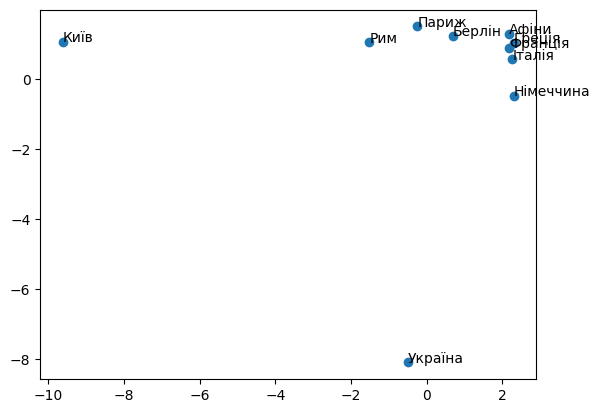

In [ ]:
words = ["Україна", "Київ",  "Німеччина", "Берлін", "Франція", "Париж", "Італія", "Рим", "Греція", "Афіни"]
visualize(words, model)

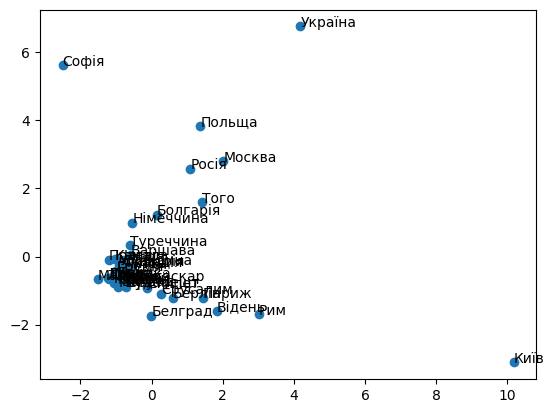

In [ ]:
unique_values = set(data.values.flatten())
unique_values_list = list(unique_values)
visualize(unique_values_list, model)